# 02 - Exploring the training data

**The big picture:** before building a model, look at the data and decide what the model should (and should not) use.

**One rule:** this notebook opens `train.csv` only. The test set stays locked away, so nothing we decide here can be
influenced by it.

Questions: (1) Is the data sound? (2) Which features separate churners from loyal customers? (3) Which columns are
redundant? (4) Do "neutral" columns secretly encode `gender` or `SeniorCitizen` (the proxy question from Project 1)?

## 1. Setup and load the training data
**If asked:** *"I explored only the training split, so no decision about the model was made with test data."*

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # the project folder
FIGS = ROOT / "docs" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(ROOT / "data" / "processed" / "train.csv")              # training customers ONLY

# Chart style: blue = retained, orange = churned (a colour-blind-safe pair)
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#898781"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e1e0d9", "axes.axisbelow": True, "font.size": 9,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})

print(f"{len(train):,} training customers")

4,930 training customers


## 2. Is the data sound?
**What:** counts of missing values, duplicates and the churn share.
**Why:** a model built on broken data is broken. The 7 customers with `TotalCharges = 0` are brand-new (tenure 0)
customers who have not been billed yet; `clean.py` set them to 0 on purpose.

In [2]:
print(f"Churn rate (train):       {train['churn_flag'].mean():.2%}   ({int(train['churn_flag'].sum()):,} churned)")
print(f"Missing cells:            {int(train.isna().sum().sum())}")
print(f"Duplicate customer IDs:   {int(train['customerID'].duplicated().sum())}")
zero = train["TotalCharges"] == 0
print(f"TotalCharges = 0:         {int(zero.sum())} customers, all with tenure 0: {bool((train.loc[zero, 'tenure'] == 0).all())}")

Churn rate (train):       26.53%   (1,308 churned)
Missing cells:            0
Duplicate customer IDs:   0
TotalCharges = 0:         7 customers, all with tenure 0: True


## 3. Numbers: tenure and monthly charges
**What:** how long customers stayed and what they pay, churned (orange) vs retained (blue).
**If asked:** *"Churners are mostly new customers on higher bills."*

tenure        MonthlyCharges       
        mean median           mean median
Churn                                    
No      37.6   38.0           61.3   64.4
Yes     18.4   10.0           75.0   80.0

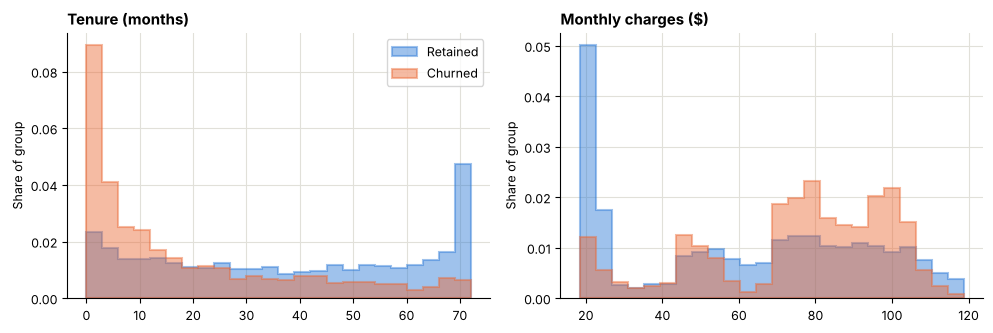

In [3]:
display(train.groupby("Churn")[["tenure", "MonthlyCharges"]].agg(["mean", "median"]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, col, title in zip(axes, ["tenure", "MonthlyCharges"], ["Tenure (months)", "Monthly charges ($)"]):
    bins = np.histogram_bin_edges(train[col], bins=24)
    for label, colour, name in (("No", BLUE, "Retained"), ("Yes", ORANGE, "Churned")):
        ax.hist(train.loc[train["Churn"] == label, col], bins=bins, density=True, histtype="stepfilled",
                color=colour, alpha=0.45, edgecolor=colour, linewidth=1.5, label=name)
    ax.set_title(title)
    ax.set_ylabel("Share of group")
axes[0].legend()
fig.tight_layout()
fig.savefig(FIGS / "eda_01_numeric_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Categories: churn rate by level
**What:** for six important columns, the share of customers in each level who churned. The dashed line is the overall rate.
**If asked:** *"Month-to-month contracts, fibre internet, no security or tech support, and electronic-check payment all
sit well above the average churn rate."*

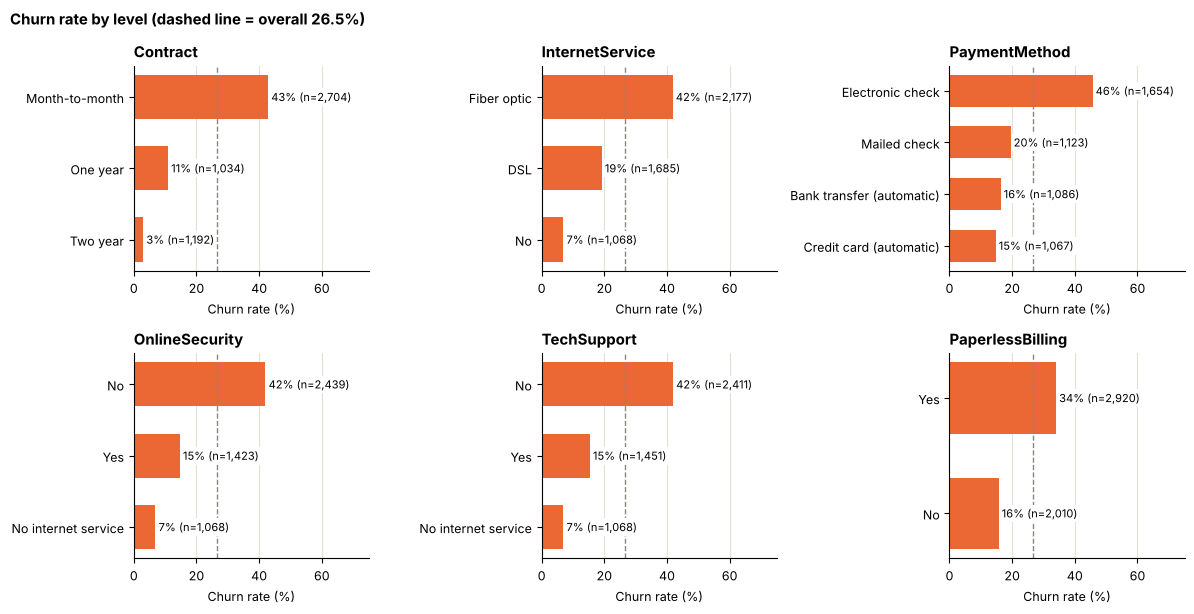

In [4]:
panels = ["Contract", "InternetService", "PaymentMethod", "OnlineSecurity", "TechSupport", "PaperlessBilling"]
overall = train["churn_flag"].mean()

fig, axes = plt.subplots(2, 3, figsize=(12, 6.2))
for ax, col in zip(axes.ravel(), panels):
    g = train.groupby(col)["churn_flag"].agg(["mean", "size"]).sort_values("mean")
    ax.barh(g.index, g["mean"] * 100, color=ORANGE, height=0.62)
    for y, (rate, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(rate * 100 + 1, y, f"{rate:.0%} (n={n:,})", va="center", fontsize=8,
                bbox=dict(facecolor="white", edgecolor="none", pad=1.5), zorder=5)
    ax.axvline(overall * 100, color=GREY, linestyle="--", linewidth=1, zorder=1)
    ax.set_xlim(0, 75)
    ax.set_title(col)
    ax.set_xlabel("Churn rate (%)")
    ax.grid(axis="y", visible=False)
fig.suptitle(f"Churn rate by level (dashed line = overall {overall:.1%})", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIGS / "eda_02_churn_rate_by_category.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Which columns are most linked to churn? (Cramér's V)
**What:** Cramér's V is a 0-to-1 score for how strongly two categorical columns are linked (0 = unrelated).
A small built-in correction stops columns with many levels from looking more related than they really are.
Numbers are cut into five equal-sized bands for this step only.
**If asked:** *"It is a descriptive ranking, not proof of cause."*

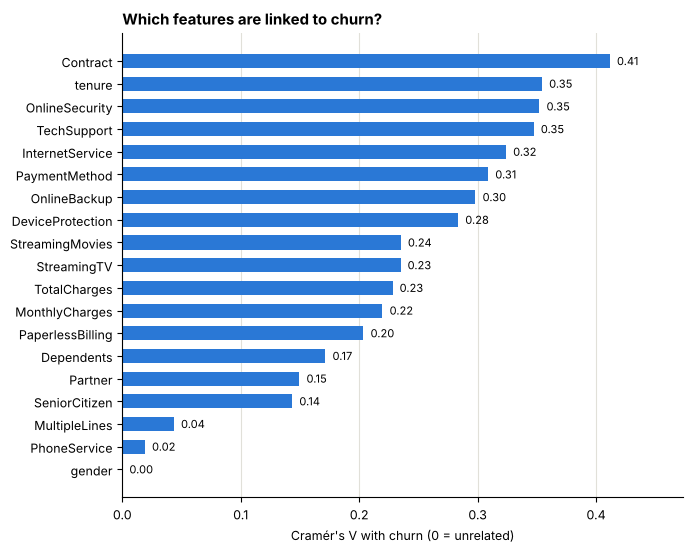

,Cramér's V
Contract,0.41
tenure,0.35
OnlineSecurity,0.35
TechSupport,0.35
InternetService,0.32
PaymentMethod,0.31


In [5]:
def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    r, k = table.shape
    phi2 = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))                 # bias-corrected
    r_c, k_c = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2 / min(k_c - 1, r_c - 1)))

# A table where every feature is turned into categories
skip = {"customerID", "Churn", "churn_flag", "tenure_bucket", "addon_count"}
feature_cols = [c for c in train.columns if c not in skip]
cats = pd.DataFrame(index=train.index)
for c in feature_cols:
    if c == "SeniorCitizen":
        cats[c] = train[c].map({0: "Non-senior", 1: "Senior"})
    elif pd.api.types.is_numeric_dtype(train[c]):
        cats[c] = pd.qcut(train[c], 5, duplicates="drop").astype(str)
    else:
        cats[c] = train[c].astype(str)

v = pd.Series({c: cramers_v(cats[c], train["Churn"]) for c in feature_cols}).sort_values()

fig, ax = plt.subplots(figsize=(7, 5.6))
ax.barh(v.index, v.values, color=BLUE, height=0.62)
for y, val in enumerate(v.values):
    ax.text(val + 0.006, y, f"{val:.2f}", va="center", fontsize=8)
ax.set_xlim(0, v.max() * 1.15)
ax.set_xlabel("Cramér's V with churn (0 = unrelated)")
ax.set_title("Which features are linked to churn?")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGS / "eda_03_cramers_v_vs_churn.png", dpi=160, bbox_inches="tight")
plt.show()
v.sort_values(ascending=False).head(6).round(2).to_frame("Cramér's V")

## 6. Redundant columns
**What:** two checks for columns that repeat each other.
- `TotalCharges` is roughly `tenure x MonthlyCharges`. Keeping all three splits credit between them.
- "No internet service" in the six add-on columns always means the same thing as `InternetService = No` (and
  "No phone service" repeats `PhoneService = No`).

**If asked:** *"I dropped TotalCharges, and the model treats 'No internet service' as plain 'No' because that
information is already in InternetService."*

In [6]:
implied = train["tenure"] * train["MonthlyCharges"]
print(f"Correlation between TotalCharges and tenure x MonthlyCharges: {np.corrcoef(train['TotalCharges'], implied)[0, 1]:.4f}\n")

addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
exact_repeat = {c: bool((train[c].eq("No internet service") == train["InternetService"].eq("No")).all()) for c in addons}
exact_repeat["MultipleLines (vs PhoneService)"] = bool(
    (train["MultipleLines"].eq("No phone service") == train["PhoneService"].eq("No")).all())
pd.Series(exact_repeat, name="'No ... service' is an exact repeat?").to_frame()

Correlation between TotalCharges and tenure x MonthlyCharges: 0.9996



,'No ... service' is an exact repeat?
OnlineSecurity,True
OnlineBackup,True
DeviceProtection,True
TechSupport,True
StreamingTV,True
StreamingMovies,True
MultipleLines (vs PhoneService),True


## 7. Proxy check: do other columns hint at gender or senior status?
**What:** for `gender` and `SeniorCitizen`, the five columns most linked to each.
**Why:** if a "neutral" column predicts a protected attribute, removing the protected column does not remove its influence.
**If asked:** *"Gender is linked to nothing, but senior status is linked to internet type, tech support and monthly
charges, so I audit outcomes by group later instead of assuming that dropping the column is enough."*

In [7]:
def top_links(col, k=5):
    others = [c for c in feature_cols if c != col]
    return pd.Series({c: cramers_v(cats[col], cats[c]) for c in others}).sort_values(ascending=False).head(k).round(3)

display(top_links("gender").to_frame("gender: Cramér's V"))
display(top_links("SeniorCitizen").to_frame("SeniorCitizen: Cramér's V"))

print("Churn rate by gender:")
print((train.groupby("gender")["churn_flag"].mean() * 100).round(1).to_string())
print("\nChurn rate by SeniorCitizen (0 = no, 1 = yes):")
print((train.groupby("SeniorCitizen")["churn_flag"].mean() * 100).round(1).to_string())

,gender: Cramér's V
OnlineSecurity,0.033
TechSupport,0.021
Contract,0.018
tenure,0.017
StreamingMovies,0.013


,SeniorCitizen: Cramér's V
InternetService,0.261
TechSupport,0.222
MonthlyCharges,0.216
Dependents,0.212
OnlineSecurity,0.199


Churn rate by gender:
gender
Female    26.3
Male      26.8

Churn rate by SeniorCitizen (0 = no, 1 = yes):
SeniorCitizen
0    23.7
1    41.1


## 8. Decisions for the model (all based on the training data above)

| What we saw | What we do |
|---|---|
| `TotalCharges` is almost `tenure x MonthlyCharges` (correlation 0.9996) | **Drop `TotalCharges`.** |
| "No internet service" and "No phone service" only repeat other columns | **Treat them as plain "No"** (a small step inside the model pipeline). |
| `gender` has no link to churn (26.3% vs 26.8%) and no column encodes it | **Not a model input.** Kept in the data for the group audit. |
| `SeniorCitizen` churns much more (41.1% vs 23.7%) and is partly encoded by `InternetService`, `TechSupport`, `MonthlyCharges`, `Dependents` | **Not a model input.** Kept for the audit, which measures how the model treats seniors. |
| `tenure_bucket` and `addon_count` are made from other columns | **Not model inputs.** They exist for SQL and Power BI only. |
| Strongest links to churn: Contract, tenure, OnlineSecurity, TechSupport, InternetService, PaymentMethod | **Check later:** the model should broadly agree with this list. |
| Churn is 26.5% of customers (imbalanced, not extreme) | **No `class_weight`**, so the probabilities stay honest. |

**Model inputs (16):** `tenure`, `MonthlyCharges` (numbers) and `Partner`, `Dependents`, `PhoneService`, `MultipleLines`,
`InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`,
`Contract`, `PaperlessBilling`, `PaymentMethod` (categories).